#유튜브 인기 동영상 데이터 분석을 통한 성공 알고리즘 도출

가상진

---

### 1. 분석 목표

데이터를 기반으로 조회수와 좋아요를 극대화할 수 있는 최적의 업로드 전략을 제안하는 것

### 2. 데이터 개요
* **데이터셋 명:** 한국 유튜브 인기 동영상 데이터 (Trending YouTube Video Statistics)
* **출처:** Kaggle https://www.kaggle.com/datasets/datasnaek/youtube-new/data
* **확보 방법:**
    * 위 Kaggle 오픈 데이터셋에서 제공하는 `KRvideos.csv` (데이터 원본)를 다운로드함.

    * 데이터 처리의 편의를 위해 **CSV 파일을 엑셀(.xlsx) 형식으로 변환하여 분석에 활용**

    * `KR_category_id.json` (카테고리 매핑 파일)을 다운로드하여 활용함.
* **선정 이유:**

    * 유튜브 성공 요인을 분석하기 위해서는 단순 조회수뿐만 아니라 **'업로드 시간(publish_time)', '태그(tags)', '좋아요 수(likes)' 등의 상세 메타데이터가 필수적**임.

    * 해당 데이터셋은 이러한 정보가 약 3만 7천 건 이상 포함되어 있어 **업로드 전략 도출**이라는 분석 목표에 가장 부합한다고 판단함.
* **데이터 크기:** 총 36,897개 (전처리 전 원본 데이터 기준)

* **주요 컬럼 설명:**
    * `title`, `channel_title`: 영상 제목 및 채널명
    * `category_id`: 동영상 카테고리 (숫자 ID → 문자열 매핑)
    * `publish_time`: 업로드 날짜 및 시간
    * `tags`: 영상에 포함된 태그 목록
    * `views`, `likes`: 조회수 및 좋아요 수
    * `comment_count`: 댓글 수

In [ ]:
# 라이브러리 불러옴
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import json
import warnings
import logging

In [ ]:
# 경고 메시지 무시
warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

In [ ]:
# 1.데이터 로드 및 전처리
df = pd.read_excel('KRvideos.xlsx')

# 데이터 소개
print("원래 데이터")
display(df.head(5))
df.info()

원래 데이터


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,RxGQe4EeEpA,17.14.11,좋아 by 민서_윤종신_좋니 답가,라푸마코리아,22.0,2017-11-13 16:07:36,"라푸마|""윤종신""|""좋니""|""좋아""|""샬레""|""민서""",156130.0,1422.0,40.0,272.0,https://i.ytimg.com/vi/RxGQe4EeEpA/default.jpg,0.0,0.0,0.0,윤종신 '좋니'의 답가 '좋아' 최초 공개!\n그 여자의 이야기를 지금 만나보세요....
1,hH7wVE8OlQ0,17.14.11,JSA 귀순 북한군 총격 부상,Edward,25.0,2017-11-13 19:59:16,"JSA|""귀순""|""북한군""|""총격""|""부상""|""JSA 귀순 북한군 총격 부상""",76533.0,211.0,28.0,113.0,https://i.ytimg.com/vi/hH7wVE8OlQ0/default.jpg,0.0,0.0,0.0,[채널A단독]北 병사 현재 '의식불명'… 혈압 떨어지는 중 \n[채널A단독]우리측 ...
2,9V8bnWUmE9U,17.14.11,나몰라패밀리 운동화 영상 2탄 (빼빼로데이버젼),나몰라패밀리 핫쇼,22.0,2017-11-11 16:16:08,"아디다스|""빼빼로""|""핫쇼""|""나몰라패밀리""|""대학로""|""공연""",421409.0,5112.0,166.0,459.0,https://i.ytimg.com/vi/9V8bnWUmE9U/default.jpg,0.0,0.0,0.0,퍼가실때 꼭 출처 부탁드려요
3,0_8py-t5R80,17.14.11,"이명박 출국 현장, 놓치면 안되는 장면",미디어몽구,25.0,2017-11-12 20:19:52,"이명박|""이명박 출국금지""|""이명박 출국현장""|""이명박 바레인""|""이명박 대통령""|...",222850.0,2093.0,173.0,1219.0,https://i.ytimg.com/vi/0_8py-t5R80/default.jpg,0.0,0.0,0.0,다스는 누구겁니까 듣고 난 후 표정
4,bk55RbxiQdI,17.14.11,김장겸은 물러갔다 MBC 노조 환호와 눈물,NocutV,25.0,2017-11-13 20:08:59,"nocutV|""노컷V""|""CBS""|""mbc""|""김장겸""|""해임""|""허일후""",84466.0,1094.0,109.0,450.0,https://i.ytimg.com/vi/bk55RbxiQdI/default.jpg,0.0,0.0,0.0,김장겸 MBC 사장이 결국 해임됐다.\n\nMBC 대주주인 방송문화진흥회는 13일 ...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36897 entries, 0 to 36896
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   video_id                36741 non-null  object        
 1   trending_date           34730 non-null  object        
 2   title                   34592 non-null  object        
 3   channel_title           34575 non-null  object        
 4   category_id             34567 non-null  float64       
 5   publish_time            34567 non-null  datetime64[ns]
 6   tags                    34568 non-null  object        
 7   views                   34567 non-null  float64       
 8   likes                   34567 non-null  float64       
 9   dislikes                34567 non-null  float64       
 10  comment_count           34567 non-null  float64       
 11  thumbnail_link          34568 non-null  object        
 12  comments_disabled       34567 non-null  float6

In [ ]:
# Column값 지운 결과
print("--- [전처리] 불필요 컬럼 제거 ---")
df.drop(["video_id","trending_date", "channel_title", "dislikes", "thumbnail_link",
         "comments_disabled", "ratings_disabled",
         "video_error_or_removed", "description"], axis=1, inplace=True)

print("\ncolumn값 지운 결과\n")
display(df.head(5))
df.info()

--- [전처리] 불필요 컬럼 제거 ---

column값 지운 결과



,title,category_id,publish_time,tags,views,likes,comment_count
0,좋아 by 민서_윤종신_좋니 답가,22.0,2017-11-13 16:07:36,"라푸마|""윤종신""|""좋니""|""좋아""|""샬레""|""민서""",156130.0,1422.0,272.0
1,JSA 귀순 북한군 총격 부상,25.0,2017-11-13 19:59:16,"JSA|""귀순""|""북한군""|""총격""|""부상""|""JSA 귀순 북한군 총격 부상""",76533.0,211.0,113.0
2,나몰라패밀리 운동화 영상 2탄 (빼빼로데이버젼),22.0,2017-11-11 16:16:08,"아디다스|""빼빼로""|""핫쇼""|""나몰라패밀리""|""대학로""|""공연""",421409.0,5112.0,459.0
3,"이명박 출국 현장, 놓치면 안되는 장면",25.0,2017-11-12 20:19:52,"이명박|""이명박 출국금지""|""이명박 출국현장""|""이명박 바레인""|""이명박 대통령""|...",222850.0,2093.0,1219.0
4,김장겸은 물러갔다 MBC 노조 환호와 눈물,25.0,2017-11-13 20:08:59,"nocutV|""노컷V""|""CBS""|""mbc""|""김장겸""|""해임""|""허일후""",84466.0,1094.0,450.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36897 entries, 0 to 36896
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   title          34592 non-null  object        
 1   category_id    34567 non-null  float64       
 2   publish_time   34567 non-null  datetime64[ns]
 3   tags           34568 non-null  object        
 4   views          34567 non-null  float64       
 5   likes          34567 non-null  float64       
 6   comment_count  34567 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(2)
memory usage: 2.0+ MB


In [ ]:
# 결측치 행 제거
original_len = len(df) # 원본 개수 저장
df.dropna(axis=0, inplace=True) # 결측치가 있는 행 제거

print(f"원본 데이터 수: {original_len}")
print(f"결측치 수: {original_len - len(df)}")
print(f"결측치 제거 후 데이터 수: {len(df)}")

# 결측치 삭제 결과
print("\n결측치 삭제 결과\n")
df.info()

원본 데이터 수: 36897
결측치 수: 2330
결측치 제거 후 데이터 수: 34567

결측치 삭제 결과

<class 'pandas.core.frame.DataFrame'>
Index: 34567 entries, 0 to 36896
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   title          34567 non-null  object        
 1   category_id    34567 non-null  float64       
 2   publish_time   34567 non-null  datetime64[ns]
 3   tags           34567 non-null  object        
 4   views          34567 non-null  float64       
 5   likes          34567 non-null  float64       
 6   comment_count  34567 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(2)
memory usage: 2.1+ MB


In [ ]:
# 이상치(상하위 1%) 제거
q_low = df['views'].quantile(0.01) # 하위 1% 지점의 값
q_high = df['views'].quantile(0.99) # 상위 1% 지점의 값
outlier_df = df[(df['views'] <= q_low) | (df['views'] >= q_high)]
df = df[(df['views'] > q_low) & (df['views'] < q_high)]

print(f"조회수의 하위 1%에 해당하는 값 (q_low): {q_low}")
print(f"조회수의 상위 1%에 해당하는 값 (q_high): {q_high}")


print(f"이상치 데이터 수: {len(outlier_df)}")
print(f"이상치 제거 후 데이터 수: {len(df)}")

# 이상치 삭제 결과
print("\n이상치 삭제 결과\n")
df.info()

조회수의 하위 1%에 해당하는 값 (q_low): 9328.66
조회수의 상위 1%에 해당하는 값 (q_high): 4633472.559999985
이상치 데이터 수: 692
이상치 제거 후 데이터 수: 33875

이상치 삭제 결과

<class 'pandas.core.frame.DataFrame'>
Index: 33875 entries, 0 to 36896
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   title          33875 non-null  object        
 1   category_id    33875 non-null  float64       
 2   publish_time   33875 non-null  datetime64[ns]
 3   tags           33875 non-null  object        
 4   views          33875 non-null  float64       
 5   likes          33875 non-null  float64       
 6   comment_count  33875 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(2)
memory usage: 2.1+ MB


In [ ]:
# 파생변수 생성

# (1) 날짜 변환: 문자열로 된 시간을 '날짜 형식(datetime)'으로 변환
df['publish_time'] = pd.to_datetime(df['publish_time'])

# (2) 시간 정보 분해: 연, 월, 요일, 시간으로 쪼개서 새 컬럼 생성
df['year'] = df['publish_time'].dt.year
df['month'] = df['publish_time'].dt.month
df['day_of_week'] = df['publish_time'].dt.dayofweek # 0:월요일 ~ 6:일요일
df['hour'] = df['publish_time'].dt.hour             # 0시 ~ 23시

# (3) 태그 개수 세기: '|'로 연결된 태그들을 분리하여 개수를 세기
df['tags'] = df['tags'].astype(str)
df['tag_count'] = df['tags'].apply(lambda x: len(x.split('|')))

# (4) 제목 길이 세기
df['title_length'] = df['title'].astype(str).apply(len)

display(df.head(5))
df.info()

,title,category_id,publish_time,tags,views,likes,comment_count,year,month,day_of_week,hour,tag_count,title_length
0,좋아 by 민서_윤종신_좋니 답가,22.0,2017-11-13 16:07:36,"라푸마|""윤종신""|""좋니""|""좋아""|""샬레""|""민서""",156130.0,1422.0,272.0,2017,11,0,16,6,18
1,JSA 귀순 북한군 총격 부상,25.0,2017-11-13 19:59:16,"JSA|""귀순""|""북한군""|""총격""|""부상""|""JSA 귀순 북한군 총격 부상""",76533.0,211.0,113.0,2017,11,0,19,6,16
2,나몰라패밀리 운동화 영상 2탄 (빼빼로데이버젼),22.0,2017-11-11 16:16:08,"아디다스|""빼빼로""|""핫쇼""|""나몰라패밀리""|""대학로""|""공연""",421409.0,5112.0,459.0,2017,11,5,16,6,26
3,"이명박 출국 현장, 놓치면 안되는 장면",25.0,2017-11-12 20:19:52,"이명박|""이명박 출국금지""|""이명박 출국현장""|""이명박 바레인""|""이명박 대통령""|...",222850.0,2093.0,1219.0,2017,11,6,20,9,26
4,김장겸은 물러갔다 MBC 노조 환호와 눈물,25.0,2017-11-13 20:08:59,"nocutV|""노컷V""|""CBS""|""mbc""|""김장겸""|""해임""|""허일후""",84466.0,1094.0,450.0,2017,11,0,20,7,23


<class 'pandas.core.frame.DataFrame'>
Index: 33875 entries, 0 to 36896
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   title          33875 non-null  object        
 1   category_id    33875 non-null  float64       
 2   publish_time   33875 non-null  datetime64[ns]
 3   tags           33875 non-null  object        
 4   views          33875 non-null  float64       
 5   likes          33875 non-null  float64       
 6   comment_count  33875 non-null  float64       
 7   year           33875 non-null  int32         
 8   month          33875 non-null  int32         
 9   day_of_week    33875 non-null  int32         
 10  hour           33875 non-null  int32         
 11  tag_count      33875 non-null  int64         
 12  title_length   33875 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int32(4), int64(2), object(2)
memory usage: 3.1+ MB


조회수, 좋아요, 댓글 수의 상관관계

                  views     likes  comment_count
views          1.000000  0.511999       0.366868
likes          0.511999  1.000000       0.560862
comment_count  0.366868  0.560862       1.000000


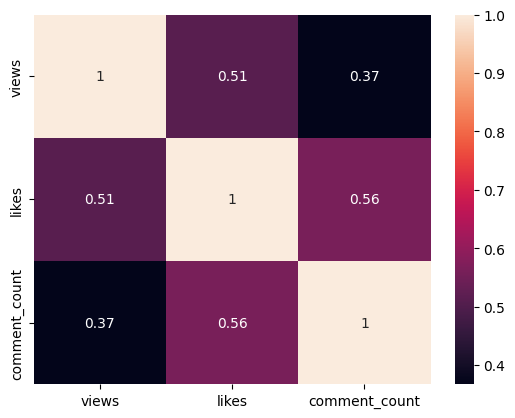

In [ ]:
print("조회수, 좋아요, 댓글 수의 상관관계\n")
corr = df[['views', 'likes', 'comment_count']].corr()
print(corr)

sns.heatmap(corr, annot=True)
plt.show()

### [분석 1] 주제(Category)별 인기 분석
* **가설:** 특정 인기 카테고리(예: 엔터테인먼트, 음악)의 조회수가 유의미하게 높을 것이다.
* **방법:** 카테고리별 평균 조회수 및 좋아요 수를 집계하여 시각화.

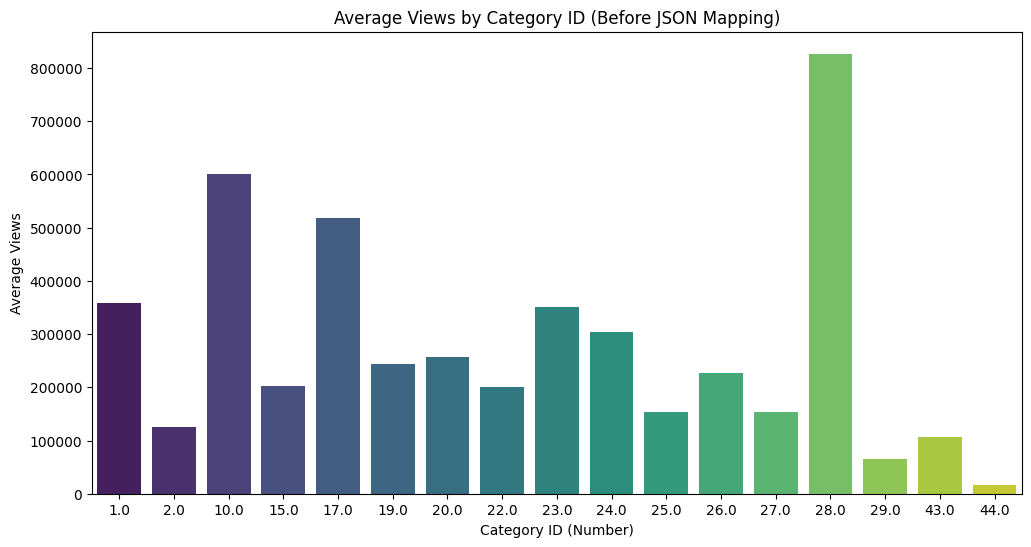

In [ ]:
# 카테고리 별 조회수 평균 (json mapping 전)
plt.figure(figsize=(12, 6))

# x축 레이블이 숫자로 나옴
sns.barplot(x=df['category_id'], y=df['views'], palette='viridis', errorbar=None)

plt.title('Average Views by Category ID (Before JSON Mapping)')
plt.xlabel('Category ID (Number)')
plt.ylabel('Average Views')
plt.show()

In [ ]:
# Json mapping 과정

# Json파일 열기
try:
    with open('KR_category_id.json', 'r') as f:
        category_data = json.load(f)

    #ID와 이름을 매칭하는 딕셔너리 생성
    id_to_category = {int(item['id']): item['snippet']['title'] for item in category_data['items']}

    #데이터프레임의 category_id 숫자를 실제 이름으로 바꿈
    df['category_name'] = df['category_id'].map(id_to_category)

except Exception as e:
    print(f"JSON 파일 로드 실패: {e}")

# JSON 적용
category_mean_name = df.groupby('category_name')[['views', 'likes']].mean().sort_values(by='views', ascending=False)

# Json 카테고리 이름 출력
print(category_mean_name.sort_values(by='views', ascending=False))

                              views         likes
category_name                                    
Science & Technology  826895.833333   9696.000000
Music                 601291.211808  40262.220937
Sports                518844.256270   2554.449291
Film & Animation      358857.787512   3340.883504
Comedy                350933.195695   6074.880137
Entertainment         303210.084619   4023.899841
Gaming                256951.030059   6508.003666
Travel & Events       242968.810526   1868.968421
Howto & Style         227692.081670   6272.653358
Pets & Animals        203291.525308   4438.088919
People & Blogs        200879.035998   2940.402776
News & Politics       154418.393460   1838.883956
Education             154155.731092   2345.945378
Autos & Vehicles      125760.245614   1293.640351
Shows                 106892.573171    437.615854
Trailers               16649.500000      3.000000


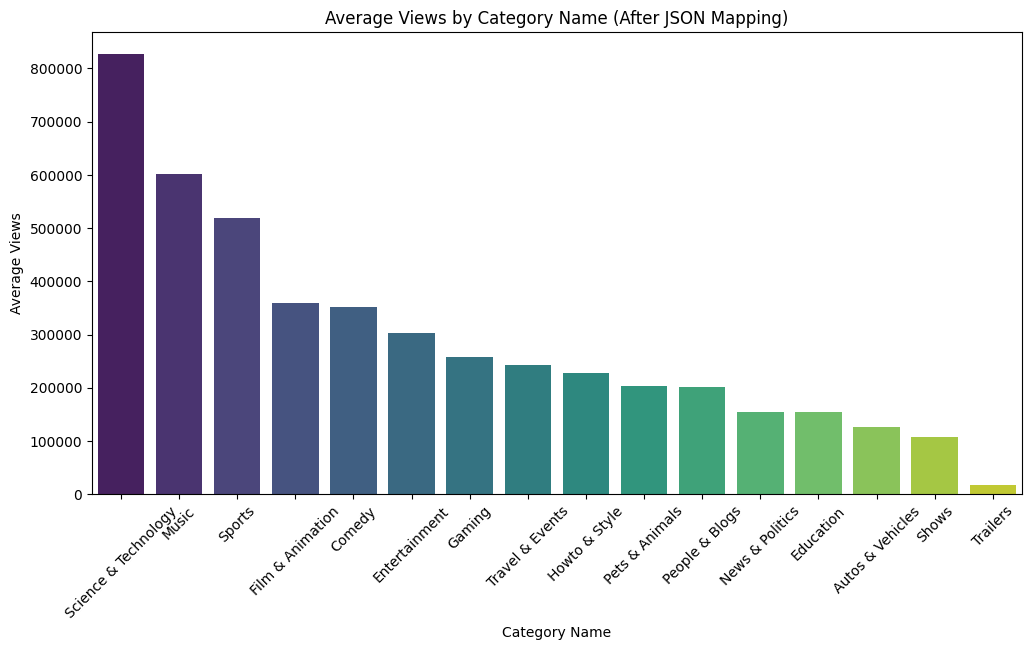

In [ ]:
# 카테고리 별 조회수 평균 (json mapping 후)
plt.figure(figsize=(12, 6))

sns.barplot(x=category_mean_name.index, y=category_mean_name['views'], palette='viridis')

plt.title('Average Views by Category Name (After JSON Mapping)')
plt.xlabel('Category Name')
plt.ylabel('Average Views')
plt.xticks(rotation=45)
plt.show()

### [분석 2] 업로드 타이밍(Time) 분석
* **가설:** 사용자들이 유튜브를 많이 보는 '퇴근 시간'이나 '주말'에 올리면 조회수가 높을 것이다.
* **방법:** 월별(Month), 시간대별(Hour), 요일별(Day) 평균 조회수 추이를 분석.

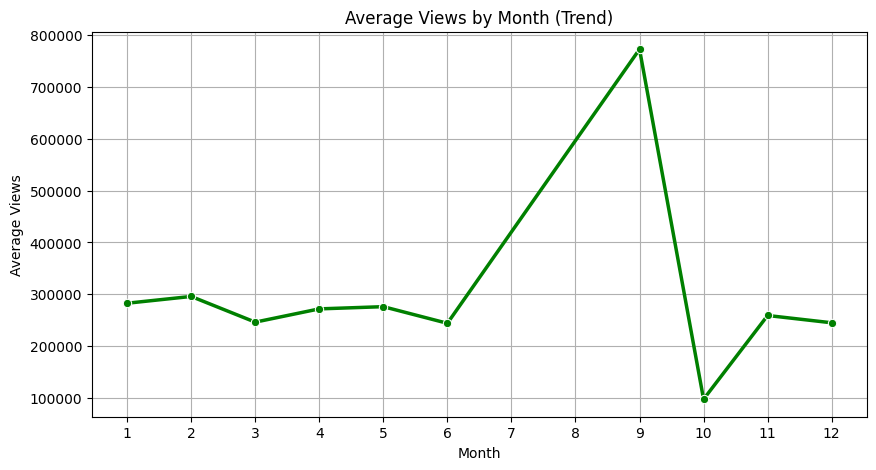

In [ ]:
# 월별 평균 조회수
month_view = df.groupby('month')['views'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=month_view.index, y=month_view.values, marker='o', color='green', linewidth=2.5)

plt.title('Average Views by Month (Trend)')
plt.xlabel('Month')
plt.ylabel('Average Views')
plt.grid(True)
plt.xticks(range(1, 13)) # 1월~12월 표시
plt.show()

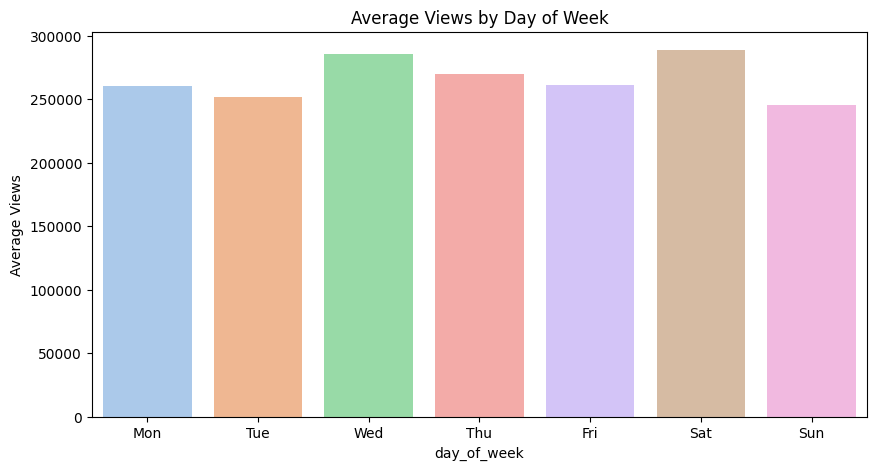

In [ ]:
# 요일별 평균 조회수 (0:월요일 ~ 6:일요일)
day_view = df.groupby('day_of_week')['views'].mean()
plt.figure(figsize=(10, 5))

# 요일 이름으로 x축 설정
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
sns.barplot(x=day_view.index, y=day_view.values, palette='pastel')
plt.ylabel("Average Views")
plt.xticks(ticks=range(7), labels=day_labels)
plt.title('Average Views by Day of Week')
plt.show()

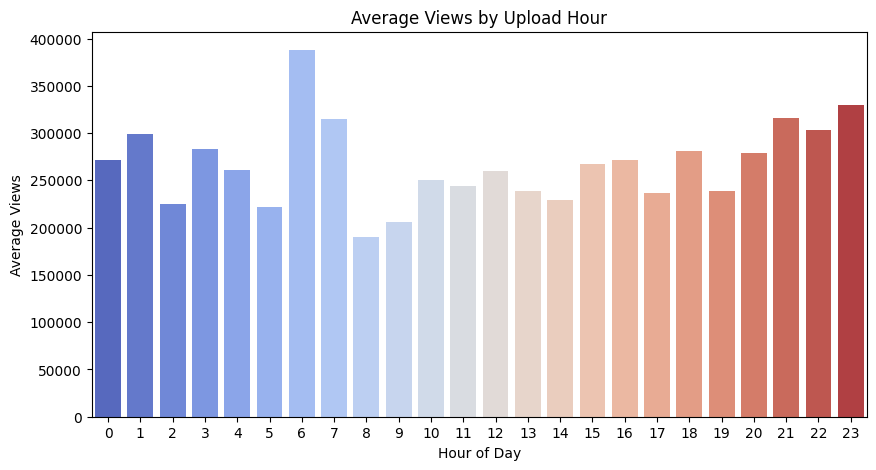

In [ ]:
# 시간대별 평균 조회수
hour_view = df.groupby('hour')['views'].mean()
plt.figure(figsize=(10, 5))

sns.barplot(x=hour_view.index, y=hour_view.values, palette='coolwarm')
plt.title('Average Views by Upload Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Views')
plt.show()

### [분석 3] 태그 개수(Tag Count) 분석
* **목표:** 태그 개수를 무조건 많이 올리는 것이 좋은지, 적당량으로 올리는게 좋은지 확인.

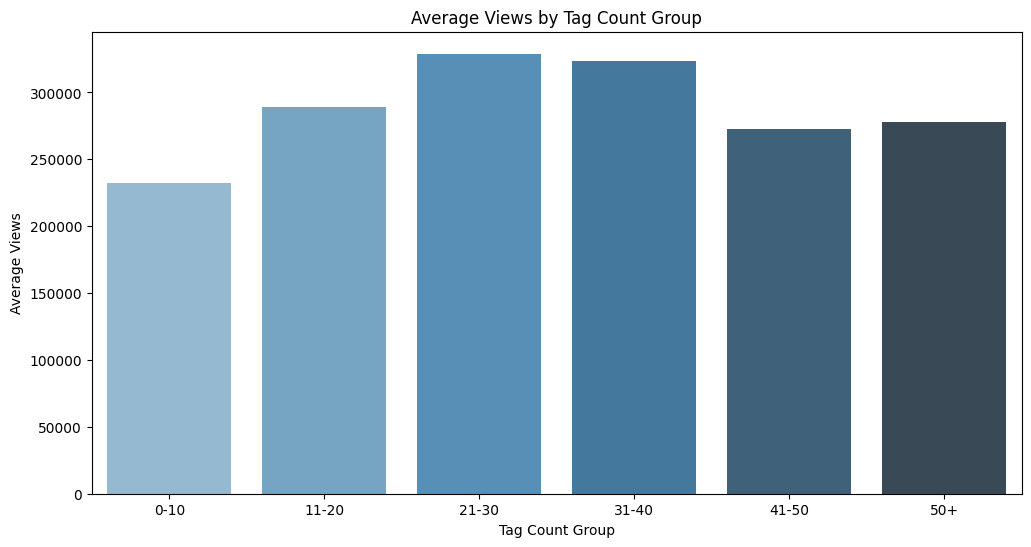

In [ ]:
bins = [0, 10, 20, 30, 40, 50, 100]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '50+']

# 태그 개수를 0-10개, 11-20개... 단위로 구간(bin)을 나누기
df['tag_group'] = pd.cut(df['tag_count'], bins=bins, labels=labels, right=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='tag_group', y='views', data=df, errorbar=None, palette='Blues_d')
plt.title('Average Views by Tag Count Group')
plt.xlabel('Tag Count Group')
plt.ylabel('Average Views')
plt.show()

### [분석 4] 머신러닝(Random Forest) 기반 중요도 검증
* **목표:** 앞서 분석한 변수들(시간, 태그, 제목 등)이 실제로 조회수 예측에 얼마나 기여하는지 검증.
* **모델:** RandomForest Regressor (설명력이 높고 비선형 관계 파악에 유리)

In [ ]:
# 학습에 사용할 변수들
features = ['category_id', 'tag_count', 'title_length', 'day_of_week', 'month', 'hour']
X = df[features]

# 정규화
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


=== Target: views 예측 모델 ===
[views] 예측 모델 성능 (R2 Score): 0.61


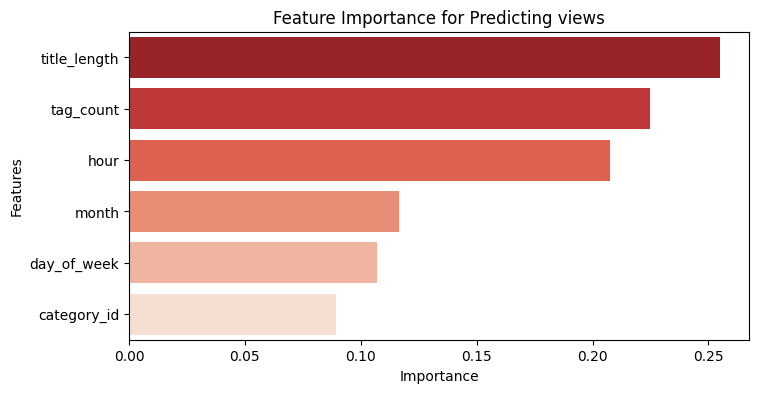

-> 'views' 예측에 가장 중요한 변수: title_length

=== Target: likes 예측 모델 ===
[likes] 예측 모델 성능 (R2 Score): 0.63


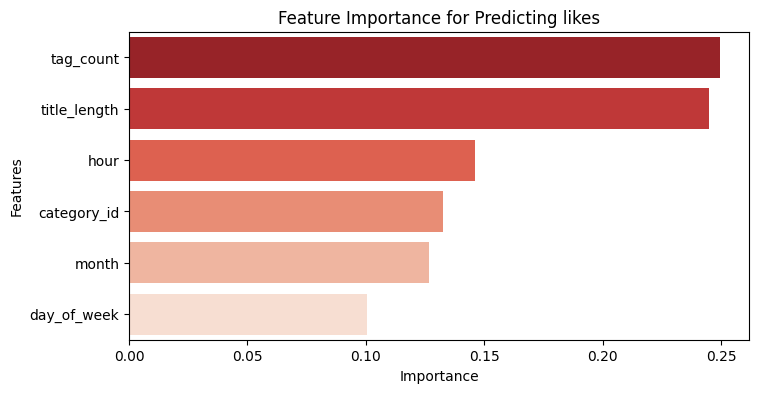

-> 'likes' 예측에 가장 중요한 변수: tag_count


In [ ]:
# 예측하고자 하는 목표(Target)는 조회수(views)와 좋아요(likes)
targets = ['views', 'likes']

for target_name in targets:
    print(f"\n=== Target: {target_name} 예측 모델 ===")
    y = df[target_name] # 예측할 정답 데이터

    # 전체 데이터를 학습용(80%)과 테스트용(20%)으로 나눔
    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

    # 모델 생성 및 학습 (나무 100개를 사용하는 랜덤 포레스트)
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)

    # 예측 및 점수 확인 (R2 Score: 1에 가까울수록 예측을 잘함)
    y_pred = rf.predict(X_test)
    score = r2_score(y_test, y_pred)

    # 모델 결과 해석 출력
    print(f"[{target_name}] 예측 모델 성능 (R2 Score): {score:.2f}")

    # 변수 중요도 시각화
    importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=importances.values, y=importances.index, palette='Reds_r')
    plt.title(f'Feature Importance for Predicting {target_name}')
    plt.xlabel('Importance')
    plt.ylabel('Features')
    plt.show()

    # 가장 중요한 변수 출력
    top_feature = importances.index[0]
    print(f"-> '{target_name}' 예측에 가장 중요한 변수: {top_feature}")


1.인기 카테고리: Science & Technology
2.골든 타임: 6시
3.AI 분석 결과: 성공을 가르는 제1요소는 title_length


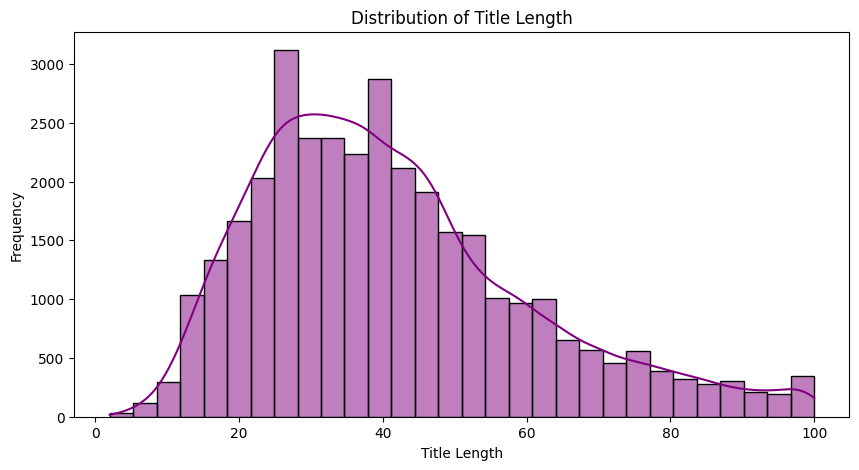

In [ ]:
# 1. [주제] 가장 조회수가 높았던 카테고리 추출
top_category = category_mean_name.index[0]
print(f"1.인기 카테고리: {top_category}")

# 2. [시간] 조회수가 가장 높은 시간대 추출
best_hour = hour_view.idxmax()
print(f"2.골든 타임: {best_hour}시")

# 3. [핵심] 다시 학습하여 최우선 변수 추출
y_views = df['views']
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_scaled, y_views, test_size=0.2, random_state=42)

rf_views = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_views.fit(X_train_v, y_train_v)

# 중요도 추출
importances_views = pd.Series(rf_views.feature_importances_, index=features).sort_values(ascending=False)
top_feature_name = importances_views.index[0]

print(f"3.AI 분석 결과: 성공을 가르는 제1요소는 {top_feature_name}")

# 제목 길이 분포 시각화
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], bins=30, kde=True, color='purple')
plt.title('Distribution of Title Length')
plt.xlabel('Title Length')
plt.ylabel('Frequency')
plt.show()

#최종 결론

**1. [When] 업로드 타이밍이 생명이다.**
   - **요일:** 토요일이 압도적으로 유리합니다.
   - **시간:** 저녁이 아닌, 하루의 시작인 **오전 6시**가 최고의 골든 타임입니다.

**2. [What] 인기 카테고리를 선점하라.**
   - 'Science & Technology' 분야가 압도적인 조회수를 기록했습니다.

**3. [How] 제목 길이와 태그 관리가 핵심이다.**
   - 조회수(Views): 머신러닝 분석 결과 제목 길이(Title Length)가 가장 중요한 변수였습니다. 충분한 정보를 담은 제목이 클릭을 유도합니다.

   - 좋아요(Likes): 시청 만족도에는 태그 개수(Tag Count)가 핵심입니다. 무조건 많이 다는 것보다 데이터가 증명한 20~30개 수준을 유지하세요.

> **한 줄 요약:**
> **"토요일 오전 6시에, Science & Technology 분야를 올리되, 긴 제목(대략 25자 ~ 40자)으로 클릭을 유도하며 20~30개의 태그로 만족도를 높여라!"**